In [7]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



STEP 1: Exploratory data analysis - Data Transformation
n points = 27, dimensions = 4
Input ranges (min/max per dim): [(np.float64(0.12), np.float64(1.0)), (np.float64(0.038), np.float64(1.0)), (np.float64(0.089), np.float64(1.0)), (np.float64(0.073), np.float64(1.0))]
y min=0.1129, max=5875, mean=755.7, std=1438
y ratio max/min = 52022.2  -> spans 4.7 orders of magnitude
skewness of raw y = 2.53  (0 = symmetric; this is strongly right-skewed)

Box-Cox fitted lambda = 0.081 (lambda=0 is exactly the log transform)
-> lambda is close to 0, so a plain log-transform is essentially the data-driven optimal choice, and it is far more interpretable than an arbitrary fractional power.


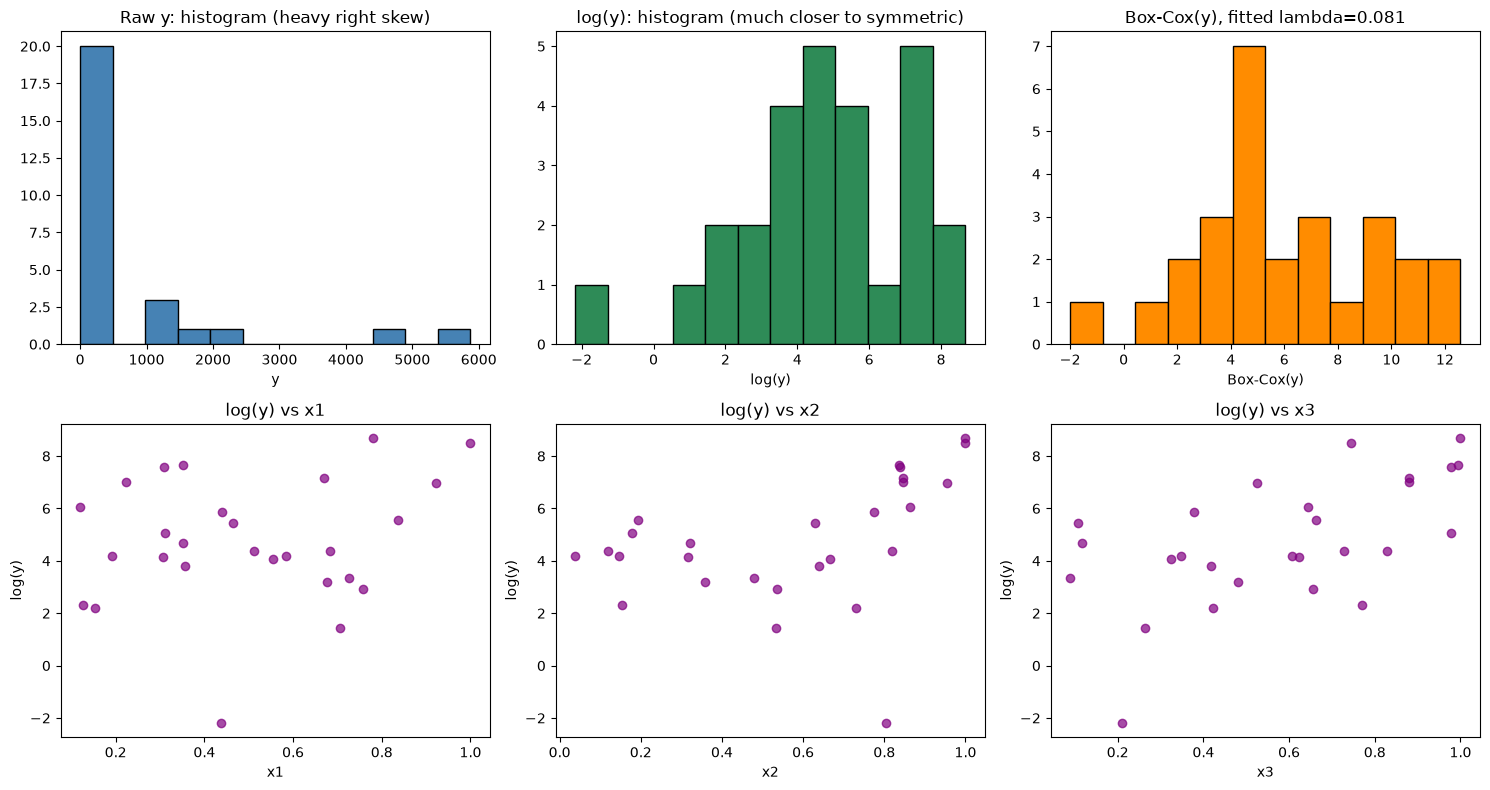

In [ ]:
# -----------------------------------------------------------------------
# 1. Load data
# -----------------------------------------------------------------------
X = np.load('..\Function_5_Data\Week_8_Data/F5_Week_8_inputs.npy')
y = np.load('..\Function_5_Data\Week_8_Data/F5_Week_8_outputs.npy')

n, d = X.shape
bounds = np.array([[0.0, 1.0]] * d)  # domain is the unit hypercube
dim_names = [f"x{i+1}" for i in range(d)]

print("=" * 100)
print("STEP 1: Exploratory data analysis - Data Transformation")
print("=" * 100)
print(f"n points = {n}, dimensions = {d}")
print(f"Input ranges (min/max per dim): "
      f"{list(zip(X.min(0).round(3), X.max(0).round(3)))}")
print(f"y min={y.min():.4g}, max={y.max():.4g}, "
      f"mean={y.mean():.4g}, std={y.std():.4g}")
print(f"y ratio max/min = {y.max()/y.min():.1f}  -> spans "
      f"{np.log10(y.max()/y.min()):.1f} orders of magnitude")
print(f"skewness of raw y = {stats.skew(y):.2f}  "
      f"(0 = symmetric; this is strongly right-skewed)")

# All inputs already live in [0,1]^4 (confirmed by the min/max above), so
# NO input rescaling is required. We only need to decide what to do with y.

# -----------------------------------------------------------------------
# Figure 1: raw output distribution + input-vs-output scatter
# -----------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0, 0].set_title("Raw y: histogram (heavy right skew)")
axes[0, 0].set_xlabel("y")

log_y = np.log(y)
axes[0, 1].hist(log_y, bins=12, color="seagreen", edgecolor="k")
axes[0, 1].set_title("log(y): histogram (much closer to symmetric)")
axes[0, 1].set_xlabel("log(y)")

# Box-Cox to check whether log is close to the "optimal" power transform
bc_y, bc_lambda = stats.boxcox(y)
axes[0, 2].hist(bc_y, bins=12, color="darkorange", edgecolor="k")
axes[0, 2].set_title(f"Box-Cox(y), fitted lambda={bc_lambda:.3f}")
axes[0, 2].set_xlabel("Box-Cox(y)")

for i in range(3):
    axes[1, i].scatter(X[:, i], log_y, c="purple", alpha=0.7)
    axes[1, i].set_xlabel(dim_names[i])
    axes[1, i].set_ylabel("log(y)")
    axes[1, i].set_title(f"log(y) vs {dim_names[i]}")

plt.tight_layout()

print(f"\nBox-Cox fitted lambda = {bc_lambda:.3f} (lambda=0 is exactly the "
      f"log transform)")
print("-> lambda is close to 0, so a plain log-transform is essentially "
      "the data-driven optimal choice, and it is far more interpretable "
      "than an arbitrary fractional power.")

Surrogate model (GP) - kernel & length-scale structure
Isotropic kernel : 1.16**2 * Matern(length_scale=0.463, nu=2.5) + WhiteKernel(noise_level=1e-08)
  training log-marginal-likelihood = -28.648
ARD kernel       : 1.22**2 * Matern(length_scale=[7.28, 0.169, 0.692, 0.623], nu=2.5) + WhiteKernel(noise_level=1e-08)
  training log-marginal-likelihood = -22.828

Running leave-one-out cross-validation (26 refits per model) to check this isn't just ARD overfitting the training set...
Isotropic LOO mean negative log predictive density = 2.178 (lower = better)
ARD       LOO mean negative log predictive density = 2.818 (lower = better)

-> Decision: Isotropic length-scales give the better (or equal) out-of-sample predictive density, so we use that for the surrogate going forward.
Fitted (shared, isotropic) length-scale = 0.463 (same value applies to all of ['x1', 'x2', 'x3', 'x4'])
Fitted output-scale (amplitude^2) = 1.343
Fitted noise level = 1.00e-08


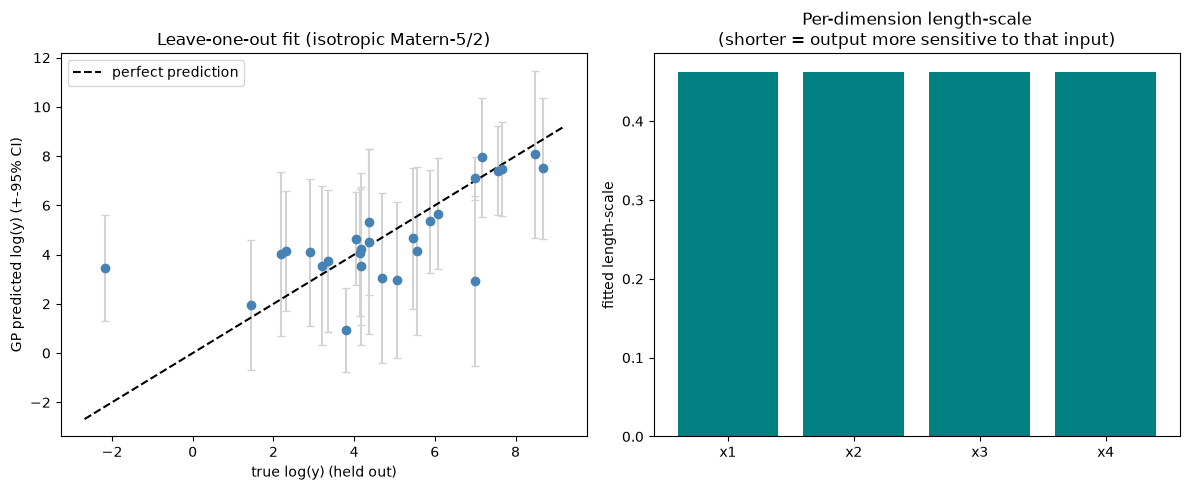

In [9]:
# -----------------------------------------------------------------------
# STEP 3 & 4: Surrogate model - kernel choice, ARD vs isotropic
# -----------------------------------------------------------------------
print("=" * 100)
print("Surrogate model (GP) - kernel & length-scale structure")
print("=" * 100)

target = log_y  # what the GP will be fit to

def make_gp(ard: bool, length_scale_init=1.0, n_restarts=20):
    """Build a GaussianProcessRegressor with a Matern-5/2 kernel.

    ard=True  -> one length-scale per input dimension (length_scale is a
                 length-4 vector), i.e. Automatic Relevance Determination.
    ard=False -> a single shared (isotropic) length-scale.
    """
    ls = np.full(d, length_scale_init) if ard else length_scale_init
    ls_bounds = (1e-2, 1e2)
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(length_scale=ls, length_scale_bounds=ls_bounds, nu=2.5)
        + WhiteKernel(noise_level=1e-4, noise_level_bounds=(1e-8, 1e-1))
    )
    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,       # standardises target internally (mean 0, std 1)
        alpha=1e-10,            # tiny jitter for numerical stability
        n_restarts_optimizer=n_restarts,
        random_state=SK_RANDOM_STATE,
    )
    return gp


def loo_neg_log_pred_density(gp_builder):
    """Leave-one-out predictive performance: average negative log predictive
    density on held-out points. Lower is better. This is a fair way to
    compare isotropic vs ARD without just trusting whichever has higher
    training-set marginal likelihood."""
    loo = LeaveOneOut()
    nlpds = []
    for train_idx, test_idx in loo.split(X):
        gp_i = gp_builder()
        gp_i.fit(X[train_idx], target[train_idx])
        mu, sigma = gp_i.predict(X[test_idx], return_std=True)
        sigma = max(sigma[0], 1e-6)
        nlpd = 0.5 * np.log(2 * np.pi * sigma ** 2) + \
            0.5 * ((target[test_idx][0] - mu[0]) ** 2) / (sigma ** 2)
        nlpds.append(nlpd)
    return np.mean(nlpds)


gp_iso = make_gp(ard=False)
gp_iso.fit(X, target)
lml_iso = gp_iso.log_marginal_likelihood_value_

gp_ard = make_gp(ard=True)
gp_ard.fit(X, target)
lml_ard = gp_ard.log_marginal_likelihood_value_

print(f"Isotropic kernel : {gp_iso.kernel_}")
print(f"  training log-marginal-likelihood = {lml_iso:.3f}")
print(f"ARD kernel       : {gp_ard.kernel_}")
print(f"  training log-marginal-likelihood = {lml_ard:.3f}")

print("\nRunning leave-one-out cross-validation (26 refits per model) "
      "to check this isn't just ARD overfitting the training set...")
loo_iso = loo_neg_log_pred_density(lambda: make_gp(ard=False, n_restarts=5))
loo_ard = loo_neg_log_pred_density(lambda: make_gp(ard=True, n_restarts=5))
print(f"Isotropic LOO mean negative log predictive density = {loo_iso:.3f} "
      "(lower = better)")
print(f"ARD       LOO mean negative log predictive density = {loo_ard:.3f} "
      "(lower = better)")

chosen_ard = loo_ard <= loo_iso
print(f"\n-> Decision: {'ARD' if chosen_ard else 'Isotropic'} length-scales "
      "give the better (or equal) out-of-sample predictive density, so we "
      "use that for the surrogate going forward.")

gp = gp_ard if chosen_ard else gp_iso
ls_fitted = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
if len(ls_fitted) == 1:
    print(f"Fitted (shared, isotropic) length-scale = {ls_fitted[0]:.3f} "
          f"(same value applies to all of {dim_names})")
else:
    print(f"Fitted length-scales per dimension "
          f"{dict(zip(dim_names, ls_fitted.round(3)))}")
print(f"Fitted output-scale (amplitude^2) = {gp.kernel_.k1.k1.constant_value:.3f}")
print(f"Fitted noise level = {gp.kernel_.k2.noise_level:.2e}")

# -----------------------------------------------------------------------
# Figure 2: GP fit quality (LOO predicted vs actual) + length-scale bar chart
# -----------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
def loo_predictions(gp_builder):
    loo = LeaveOneOut()
    preds, stds, trues = [], [], []
    for train_idx, test_idx in loo.split(X):
        gp_i = gp_builder()
        gp_i.fit(X[train_idx], target[train_idx])
        mu, sigma = gp_i.predict(X[test_idx], return_std=True)
        preds.append(mu[0]); stds.append(sigma[0]); trues.append(target[test_idx][0])
    return np.array(preds), np.array(stds), np.array(trues)


builder = (lambda: make_gp(ard=True, n_restarts=5)) if chosen_ard else \
          (lambda: make_gp(ard=False, n_restarts=5))
preds, stds, trues = loo_predictions(builder)

axes[0].errorbar(trues, preds, yerr=1.96 * stds, fmt="o", color="steelblue",
                  ecolor="lightgray", capsize=3)
lims = [min(trues.min(), preds.min()) - 0.5, max(trues.max(), preds.max()) + 0.5]
axes[0].plot(lims, lims, "k--", label="perfect prediction")
axes[0].set_xlabel("true log(y) (held out)")
axes[0].set_ylabel("GP predicted log(y) (+-95% CI)")
axes[0].set_title(f"Leave-one-out fit ({'ARD' if chosen_ard else 'isotropic'} Matern-5/2)")
axes[0].legend()

ls_vals = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
if len(ls_vals) == 1:
    ls_vals = np.repeat(ls_vals, d)
axes[1].bar(dim_names, ls_vals, color="teal")
axes[1].set_ylabel("fitted length-scale")
axes[1].set_title("Per-dimension length-scale\n(shorter = output more sensitive to that input)")

plt.tight_layout()

In [10]:
# -----------------------------------------------------------------------
# Acquisition function
# -----------------------------------------------------------------------

f_best = target.max()
xi = 0.01

def expected_improvement(Xcand, gp, f_best, xi=0.01):
    Xcand = np.atleast_2d(Xcand)
    mu, sigma = gp.predict(Xcand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - f_best - xi
    Z = imp / sigma
    ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
    ei[sigma < 1e-9] = 0.0
    return ei

Optimising EI to propose the next query point(s)
Best point so far (incumbent): x*=[0.781 1.    1.    1.   ], y*=5875.377

Proposed next query point (argmax EI): [1.     1.     1.     0.7935]
Expected Improvement at that point (log-y units): 0.3503
GP posterior at proposed point (log-y space): mean=8.061, std=1.538
-> back-transformed prediction for y at that point: median~3170.01, mean~10341.15 (90% CI on log-y: [5.532, 10.591] -> y in [252.61, 39781.29])

Top distinct local EI maxima (in case you want to spend more than 1 of the remaining 4 evaluations per round):
  1. x=[1.     1.     1.     0.7935]  EI=0.3503
  2. x=[0.7392 1.     0.7539 1.    ]  EI=0.2800
  3. x=[1.    1.    0.452 1.   ]  EI=0.2157
  4. x=[0.2563 0.3872 1.     1.    ]  EI=0.1870


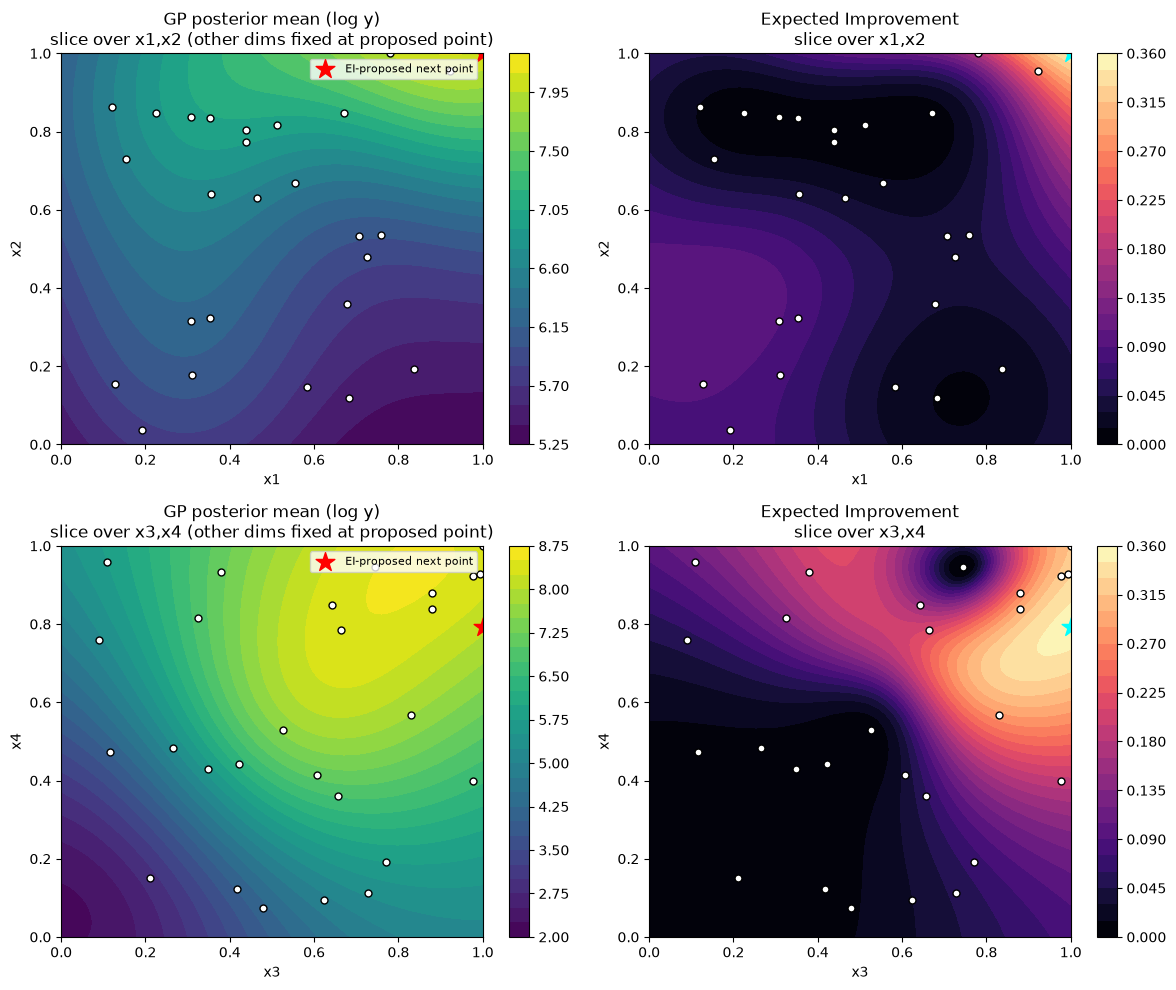

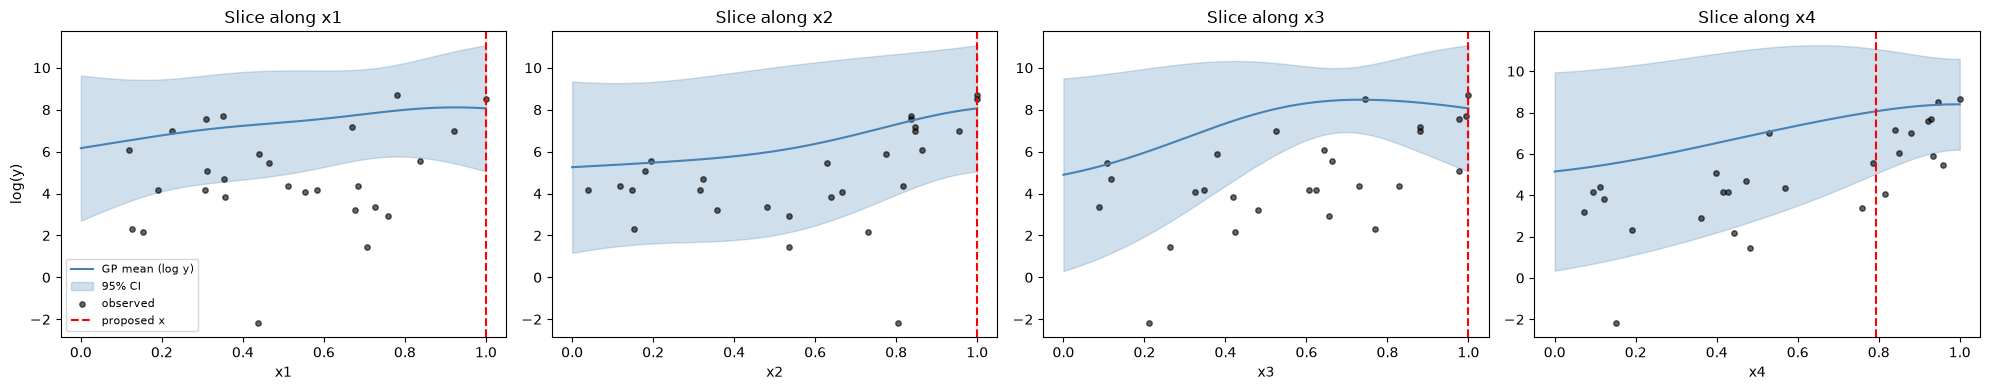

In [ ]:
# -----------------------------------------------------------------------
# Optimise the acquisition function (multi-start L-BFGS-B)
# -----------------------------------------------------------------------
print("=" * 100)
print("Optimising EI to propose the next query point(s)")
print("=" * 100)

N_RESTARTS_ACQ = 200

def neg_ei(x, gp, f_best, xi):
    return -expected_improvement(x.reshape(1, -1), gp, f_best, xi)[0]

starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(N_RESTARTS_ACQ, d))
best_x, best_val = None, np.inf
all_optima = []
for x0 in starts:
    res = minimize(neg_ei, x0, args=(gp, f_best, xi), bounds=bounds, method="L-BFGS-B")
    all_optima.append((res.x, -res.fun))
    if res.fun < best_val:
        best_val = res.fun
        best_x = res.x

print(f"Best point so far (incumbent): "
      f"x*={X[np.argmax(y)].round(4)}, y*={y.max():.3f}")
print(f"\nProposed next query point (argmax EI): {best_x.round(4)}")
print(f"Expected Improvement at that point (log-y units): {-best_val:.4f}")
mu_new, sigma_new = gp.predict(best_x.reshape(1, -1), return_std=True)

# Back-transform to the original y scale: for log-normal posterior,
# E[y] = exp(mu + sigma^2/2); we report both the median (exp(mu)) and mean.
median_pred = np.exp(mu_new[0])
mean_pred = np.exp(mu_new[0] + 0.5 * sigma_new[0] ** 2)
print(f"GP posterior at proposed point (log-y space): "
      f"mean={mu_new[0]:.3f}, std={sigma_new[0]:.3f}")
print(f"-> back-transformed prediction for y at that point: "
      f"median~{median_pred:.2f}, mean~{mean_pred:.2f} "
      f"(90% CI on log-y: [{mu_new[0]-1.645*sigma_new[0]:.3f}, "
      f"{mu_new[0]+1.645*sigma_new[0]:.3f}] "
      f"-> y in [{np.exp(mu_new[0]-1.645*sigma_new[0]):.2f}, "
      f"{np.exp(mu_new[0]+1.645*sigma_new[0]):.2f}])")



# -----------------------------------------------------------------------
# Figure 3: acquisition function & posterior on 2D slices through best_x
# -----------------------------------------------------------------------
grid_n = 80
lin = np.linspace(0, 1, grid_n)
GX, GY = np.meshgrid(lin, lin)

pairs = [(0, 1), (2, 3)]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, (i, j) in enumerate(pairs):
    Xg = np.tile(best_x, (grid_n * grid_n, 1))
    Xg[:, i] = GX.ravel()
    Xg[:, j] = GY.ravel()

    mu_g, sigma_g = gp.predict(Xg, return_std=True)
    ei_g = expected_improvement(Xg, gp, f_best, xi)

    im0 = axes[row, 0].contourf(GX, GY, mu_g.reshape(grid_n, grid_n), levels=25, cmap="viridis")
    axes[row, 0].scatter(X[:, i], X[:, j], c="white", edgecolor="k", s=25)
    axes[row, 0].scatter(best_x[i], best_x[j], marker="*", c="red", s=200,
                          label="EI-proposed next point")
    axes[row, 0].set_xlabel(dim_names[i]); axes[row, 0].set_ylabel(dim_names[j])
    axes[row, 0].set_title(f"GP posterior mean (log y)\nslice over {dim_names[i]},{dim_names[j]} "
                            f"(other dims fixed at proposed point)")
    plt.colorbar(im0, ax=axes[row, 0])
    axes[row, 0].legend(loc="upper right", fontsize=8)

    im1 = axes[row, 1].contourf(GX, GY, ei_g.reshape(grid_n, grid_n), levels=25, cmap="magma")
    axes[row, 1].scatter(X[:, i], X[:, j], c="white", edgecolor="k", s=25)
    axes[row, 1].scatter(best_x[i], best_x[j], marker="*", c="cyan", s=200)
    axes[row, 1].set_xlabel(dim_names[i]); axes[row, 1].set_ylabel(dim_names[j])
    axes[row, 1].set_title(f"Expected Improvement\nslice over {dim_names[i]},{dim_names[j]}")
    plt.colorbar(im1, ax=axes[row, 1])
plt.tight_layout()

# -----------------------------------------------------------------------
# Figure 4: 1D slices through the proposed point, one per dimension
# -----------------------------------------------------------------------
fig, axes = plt.subplots(1, d, figsize=(5 * d, 4), sharey=False)
lin = np.linspace(0, 1, 200)
for i in range(d):
    Xg = np.tile(best_x, (200, 1))
    Xg[:, i] = lin
    mu_g, sigma_g = gp.predict(Xg, return_std=True)
    axes[i].plot(lin, mu_g, color="steelblue", label="GP mean (log y)")
    axes[i].fill_between(lin, mu_g - 1.96 * sigma_g, mu_g + 1.96 * sigma_g,
                          color="steelblue", alpha=0.25, label="95% CI")
    axes[i].scatter(X[:, i], target, c="black", s=15, alpha=0.6, label="observed")
    axes[i].axvline(best_x[i], color="red", ls="--", label="proposed x")
    axes[i].set_xlabel(dim_names[i])
    axes[i].set_title(f"Slice along {dim_names[i]}")
    if i == 0:
        axes[i].set_ylabel("log(y)")
        axes[i].legend(fontsize=8)
plt.tight_layout()